<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/cosmology/cosmo_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Cosmology* — `cosmo_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Cosmology Chapter 3 — Figures

Python-generated figures for `cosmo_ch03_slides.qmd`.

## Figures generated here
| File | Slide | Description |
|------|-------|-------------|
| `cosmo_growth_modes.png` | §3.1.4 | Growing/decaying modes of δ in different epochs |
| `cosmo_transfer_function.png` | §3.1.6 | Transfer function T(k) |
| `cosmo_gaussian_fields.png` | §3.2.2 | Gaussian random fields (4-panel: n=4,3,1,0) |
| `cosmo_spherical_collapse.png` | §3.3.1 | True vs linear density contrast in spherical collapse |

## Textbook captures needed (add manually)
| File | Slide | Source |
|------|-------|--------|
| `cosmo_fig36_matter_power_spectrum.png` | §3.2.3 | Tong Fig. 36 (Planck matter P(k)) |
| `cosmo_fig37_bao_correlation.png` | §3.2.4 | Tong Fig. 37 (BAO correlation function) |
| `cosmo_fig38_cmb_sphere.png` | §3.4.2 | Tong Fig. 38 (CMB sky map) |
| `cosmo_fig39_cmb_power_spectrum.png` | §3.4.3 | Tong Fig. 39 (Planck CMB Cl) |
| `cosmo_fig40_inflation_horizon.png` | §3.5.1 | Tong Fig. 40 (inflation horizon exit diagram) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.integrate import odeint
import os

os.makedirs('figures', exist_ok=True)

# ── Dark theme palette (matches cosmo_slides.css) ────────────────────────────
BG      = '#080c14'
SURFACE = '#0f1825'
BORDER  = '#1e2d42'
TEXT    = '#e2eaf4'
MUTED   = '#7a9ab8'
GOLD    = '#e8b84b'
BLUE    = '#4ca8f0'
GREEN   = '#3ecf8e'
RED     = '#f06060'
PURPLE  = '#c084fc'
ORANGE  = '#f59e42'

def style_ax(ax, grid=True):
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=MUTED, labelsize=10)
    for spine in ax.spines.values():
        spine.set_edgecolor(BORDER)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)
    ax.title.set_color(GOLD)
    if grid:
        ax.grid(True, alpha=0.2, color=BORDER)

print('Setup complete.')

Setup complete.


## Figure 1: Growth of Density Perturbations

Fig 1 saved: cosmo_growth_modes.png


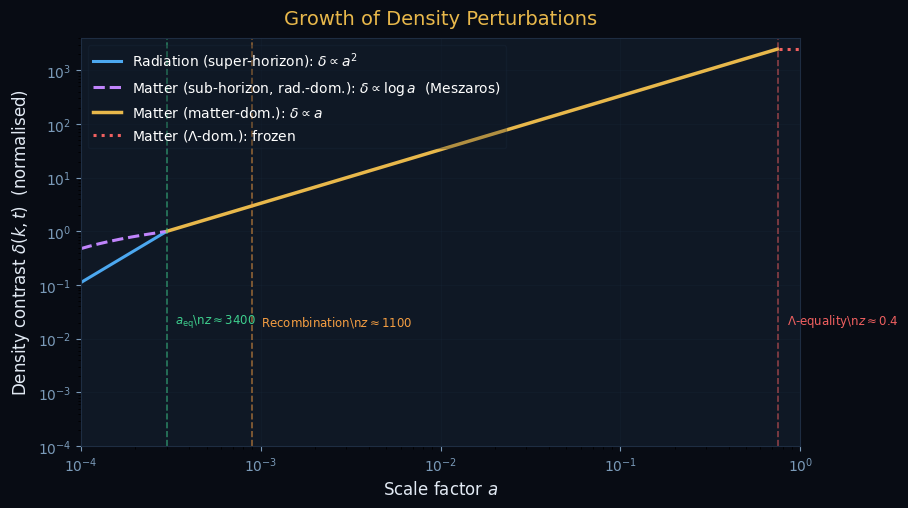

In [2]:
fig, ax = plt.subplots(figsize=(9, 5), facecolor=BG)
style_ax(ax)

# Scale factor range
a = np.logspace(-4, 0, 500)

# ── Epochs (rough boundaries) ────────────────────────────────────────────────
a_eq   = 3e-4   # matter-radiation equality
a_last = 9e-4   # last scattering / recombination
a_lam  = 0.75   # matter-Lambda equality

# ── Growing modes piecewise ──────────────────────────────────────────────────
# 1. Super-horizon radiation (any fluid): delta ~ a^2
mask_rad_super = a < a_eq
d_super = a**2 / a_eq**2   # normalised to 1 at a_eq

# 2. Sub-horizon matter in radiation-dominated era: delta ~ log(a)  (Meszaros)
mask_meszaros = a < a_eq
d_meszaros = (1 + np.log(a / a[0])) / (1 + np.log(a_eq / a[0]))
d_meszaros = np.where(d_meszaros > 0, d_meszaros, 1e-5)

# 3. Matter-dominated growing mode: delta ~ a  (normalised at a_eq)
mask_mat = (a >= a_eq) & (a <= a_lam)
d_mat = a / a_eq

# 4. Lambda-dominated: frozen
mask_lam = a > a_lam
d_lam = np.ones_like(a) * (a_lam / a_eq)

# Build composite curves
d_super_full    = np.where(a <= a_eq, d_super,    np.nan)
d_meszaros_full = np.where(a <= a_eq, d_meszaros, np.nan)
d_mat_full      = np.where((a >= a_eq) & (a <= a_lam), d_mat, np.nan)
d_frozen_full   = np.where(a >= a_lam, d_lam,   np.nan)

# Plot
ax.loglog(a, d_super_full,    color=BLUE,   lw=2.2, label=r'Radiation (super-horizon): $\delta \propto a^2$')
ax.loglog(a, d_meszaros_full, color=PURPLE, lw=2.2, ls='--',
          label=r'Matter (sub-horizon, rad.-dom.): $\delta \propto \log a$  (Meszaros)')
ax.loglog(a, d_mat_full,      color=GOLD,   lw=2.5, label=r'Matter (matter-dom.): $\delta \propto a$')
ax.loglog(a, d_frozen_full,   color=RED,    lw=2.2, ls=':', label=r'Matter ($\Lambda$-dom.): frozen')

# Epoch boundaries
for xv, lbl, col in [
    (a_eq,  r'$a_\mathrm{eq}$\n$z\approx3400$', GREEN),
    (a_last,r'Recombination\n$z\approx1100$',   ORANGE),
    (a_lam, r'$\Lambda$-equality\n$z\approx0.4$', RED),
]:
    ax.axvline(xv, color=col, lw=1.2, alpha=0.55, ls='--')
    ax.text(xv*1.12, 0.015, lbl, color=col, fontsize=8.5,
            va='bottom', rotation=0)

ax.set_xlabel('Scale factor $a$', fontsize=12)
ax.set_ylabel(r'Density contrast $\delta(k,t)$  (normalised)', fontsize=12)
ax.set_title('Growth of Density Perturbations', fontsize=14, pad=10)
ax.legend(loc='upper left', labelcolor='white', framealpha=0.25, facecolor=SURFACE,
          edgecolor=BORDER, fontsize=10)
ax.set_xlim(a[0], 1.0)
ax.set_ylim(1e-4, 4e3)

plt.tight_layout(pad=0.4)
plt.savefig('figures/cosmo_growth_modes.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
print('Fig 1 saved: cosmo_growth_modes.png')
plt.show()

## Figure 2: Transfer Function T(k)

Fig 2 saved: cosmo_transfer_function.png


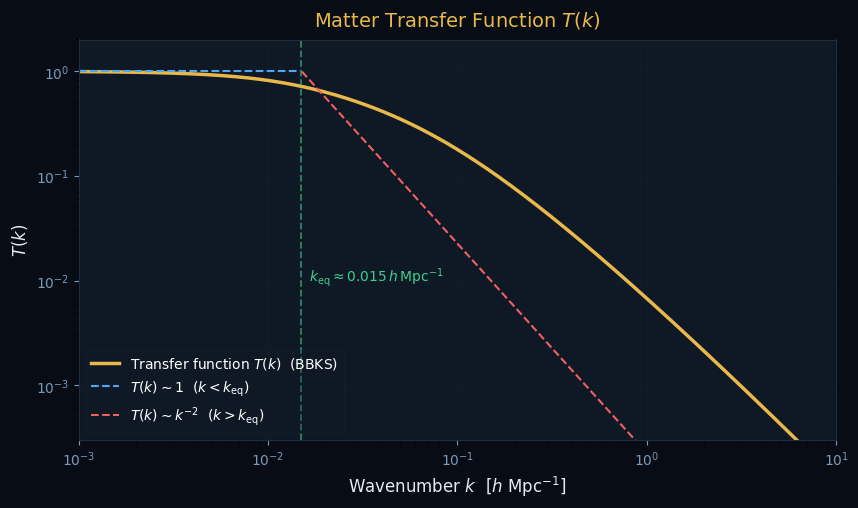

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5), facecolor=BG)
style_ax(ax)

k = np.logspace(-3, 1, 500)   # h Mpc^-1
k_eq = 0.015                   # h Mpc^-1  (approximate)

# Analytic approximation to transfer function (Bardeen et al., simplified)
# BBKS transfer function (approximate)
def T_BBKS(k, k_eq):
    """Simplified BBKS transfer function."""
    q = k / k_eq
    return np.log(1 + 0.171*q) / (0.171*q) * \
           (1 + 0.284*q + (1.18*q)**2 + (0.399*q)**3 + (0.490*q)**4)**(-0.25)

T = T_BBKS(k, k_eq)

# Asymptotic piecewise
T_low  = np.ones_like(k)                            # k < k_eq: T ~ 1
T_high = (k_eq / k)**2 * T[k >= k_eq][0] * (k[k >= k_eq][0]/k_eq)**2  # k > k_eq: T ~ (k_eq/k)^2
# Recompute cleanly
T_high_arr = np.where(k > k_eq, (k_eq/k)**2, np.nan)
T_low_arr  = np.where(k < k_eq, np.ones_like(k), np.nan)

ax.loglog(k, T, color=GOLD, lw=2.5, label='Transfer function $T(k)$  (BBKS)')
ax.loglog(k, T_low_arr,  color=BLUE,  lw=1.5, ls='--', label=r'$T(k)\sim 1$  ($k < k_\mathrm{eq}$)')
ax.loglog(k, T_high_arr, color=RED,   lw=1.5, ls='--', label=r'$T(k)\sim k^{-2}$  ($k > k_\mathrm{eq}$)')

ax.axvline(k_eq, color=GREEN, lw=1.3, alpha=0.6, ls='--')
ax.text(k_eq*1.1, 0.01, r'$k_\mathrm{eq}\approx 0.015\,h\,\mathrm{Mpc}^{-1}$',
        color=GREEN, fontsize=10)

ax.set_xlabel(r'Wavenumber $k$  [$h$ Mpc$^{-1}$]', fontsize=12)
ax.set_ylabel('$T(k)$', fontsize=12)
ax.set_title('Matter Transfer Function $T(k)$', fontsize=14, pad=10)
ax.legend(loc='lower left', labelcolor='white', framealpha=0.25, facecolor=SURFACE,
          edgecolor=BORDER, fontsize=10)
ax.set_xlim(k[0], k[-1])
ax.set_ylim(3e-4, 2.0)

plt.tight_layout(pad=0.4)
plt.savefig('figures/cosmo_transfer_function.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
print('Fig 2 saved: cosmo_transfer_function.png')
plt.show()

## Figure 3: Gaussian Random Fields — 4-panel (n = 4, 3, 1, 0)

Fig 3 saved: cosmo_gaussian_fields.png


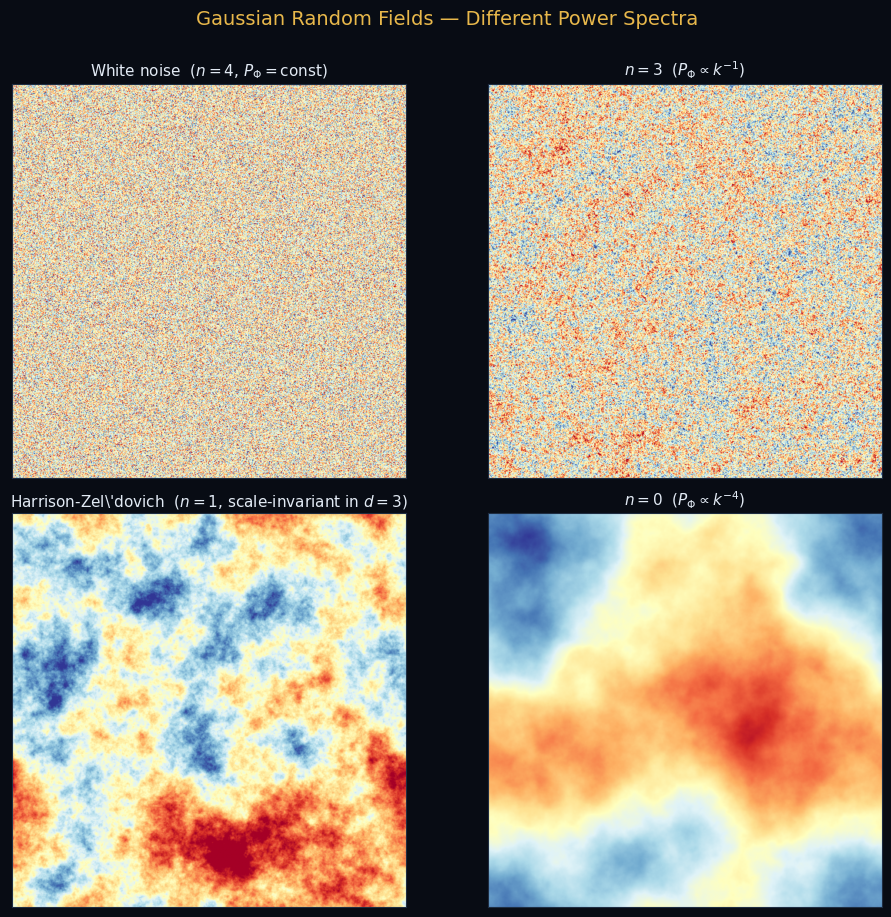

In [4]:
def make_gaussian_field_2d(N, n_spectral, seed=42):
    """Generate a 2D Gaussian random field with power spectrum P_Phi ~ k^(n-4).
    Using convention P_Phi(k) = k^(n-4), so P_delta(k) = k^n.
    """
    rng = np.random.default_rng(seed)
    # White noise in Fourier space
    noise_r = rng.standard_normal((N, N))
    noise_i = rng.standard_normal((N, N))
    noise_k = noise_r + 1j * noise_i

    # Build k grid
    kx = np.fft.fftfreq(N, d=1.0/N)   # integer wavenumbers
    ky = np.fft.fftfreq(N, d=1.0/N)
    KX, KY = np.meshgrid(kx, ky, indexing='ij')
    K = np.sqrt(KX**2 + KY**2)
    K[0, 0] = 1.0   # avoid division by zero at DC

    # Apply power spectrum P_Phi ~ k^(n-4)
    # In 2D, dimensionless: Delta^2 = k^2 P / (2pi) ~ k^n
    P_k = K**(n_spectral - 4)   # P_Phi
    P_k[0, 0] = 0.0             # zero DC

    field_k = noise_k * np.sqrt(P_k)
    field_x = np.fft.ifft2(field_k).real
    # Normalise
    field_x = (field_x - field_x.mean()) / (field_x.std() + 1e-12)
    return field_x

N = 512
cases = [
    (4, r'White noise  ($n=4$, $P_\Phi=\mathrm{const}$)', 101),
    (3, r'$n=3$  ($P_\Phi \propto k^{-1}$)',              202),
    (1, r'Harrison-Zel\'dovich  ($n=1$, scale-invariant in $d=3$)', 303),
    (0, r'$n=0$  ($P_\Phi \propto k^{-4}$)',              404),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 9), facecolor=BG)
fig.suptitle('Gaussian Random Fields — Different Power Spectra',
             color=GOLD, fontsize=14, y=1.01)

for ax, (n_spec, title, seed) in zip(axes.flat, cases):
    field = make_gaussian_field_2d(N, n_spec, seed=seed)
    ax.imshow(field, origin='lower', cmap='RdYlBu_r',
              vmin=-2.5, vmax=2.5, interpolation='bilinear')
    ax.set_title(title, color=TEXT, fontsize=11, pad=6)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(BORDER)

plt.tight_layout(pad=0.8)
plt.savefig('figures/cosmo_gaussian_fields.png', dpi=130,
            bbox_inches='tight', facecolor=BG)
print('Fig 3 saved: cosmo_gaussian_fields.png')
plt.show()

## Figure 4: Spherical Collapse — True vs. Linear Density Contrast

Fig 4 saved: cosmo_spherical_collapse.png


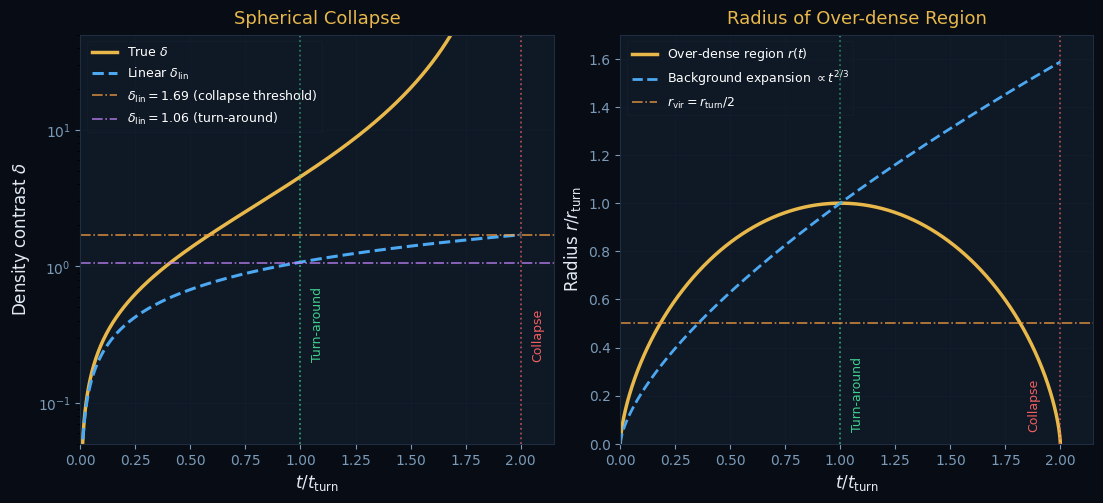


Physical checks:
  True δ at turn-around: 4.552  (expect 4.55)
  Linear δ at collapse:  1.686  (expect 1.686)
  Virialised δ:          176.7  (expect 177)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), facecolor=BG)

# ── Panel A: density contrast vs time ───────────────────────────────────────
ax = axes[0]
style_ax(ax)

phi = np.linspace(0.01, 2*np.pi - 0.01, 800)

# True density contrast (1+delta) = 9/2 * (phi - sin phi)^2 / (1 - cos phi)^3
numerator   = (phi - np.sin(phi))**2
denominator = (1 - np.cos(phi))**3
one_plus_delta = 9/2 * numerator / denominator
delta_true = one_plus_delta - 1

# Time: t(phi) = B(phi - sin phi); normalise so t_turn = pi -> 1
t_phi = phi - np.sin(phi)   # proportional to t
t_turn = np.pi - np.sin(np.pi)   # = pi
t_norm = t_phi / t_turn   # normalised so turn-around at t=1

# Linear density contrast: delta_lin ~ t^{2/3} ~ (phi^3/6)^{2/3} for small phi
# From linearised solution: delta_lin = 3/20 * (6t/B)^{2/3}
# Normalise so delta_lin = delta_true at early times
# delta_lin ~ (phi^2/2)^{2/3} at small phi (from phi-sin(phi) ~ phi^3/6, 1-cos ~ phi^2/2)
# More precise: use full phi expansion
# delta_lin(t) propto t^{2/3}, so propto (phi - sin phi)^{2/3}
delta_lin = (3/20) * (6)**(2/3) * t_norm**(2/3)
# Rescale to match at small phi (t<<t_turn)
# At phi=0.3 (well within linear regime)
idx_lin = np.searchsorted(phi, 0.3)
delta_lin = delta_lin * delta_true[idx_lin] / delta_lin[idx_lin]

# Clip true delta for display (it diverges at 2pi)
clip = 50
delta_true_plot = np.where(delta_true < clip, delta_true, np.nan)

ax.semilogy(t_norm, delta_true_plot, color=GOLD, lw=2.5, label=r'True $\delta$')
ax.semilogy(t_norm, delta_lin,       color=BLUE, lw=2.2, ls='--', label=r'Linear $\delta_\mathrm{lin}$')

# Mark turn-around and collapse
t_turn_norm = 1.0
t_col_norm  = 2.0 * (np.pi - np.sin(np.pi)) / t_turn  # = 2.0 by definition (t_col = 2 t_turn)
# Actually t_col corresponds to phi=2pi: t = 2pi - sin(2pi) = 2pi, t_turn = pi
t_col_norm_real = 2 * np.pi / np.pi  # = 2.0

ax.axvline(t_turn_norm, color=GREEN,  lw=1.3, ls=':', alpha=0.7)
ax.axvline(t_col_norm_real, color=RED, lw=1.3, ls=':', alpha=0.7)
ax.axhline(1.69, color=ORANGE, lw=1.2, ls='-.', alpha=0.8, label=r'$\delta_\mathrm{lin}=1.69$ (collapse threshold)')
ax.axhline(1.06, color=PURPLE, lw=1.2, ls='-.', alpha=0.8, label=r'$\delta_\mathrm{lin}=1.06$ (turn-around)')

ax.text(t_turn_norm+0.05, 0.2, 'Turn-around', color=GREEN, fontsize=9, rotation=90, va='bottom')
ax.text(t_col_norm_real+0.05, 0.2, 'Collapse', color=RED, fontsize=9, rotation=90, va='bottom')

ax.set_xlabel(r'$t / t_\mathrm{turn}$', fontsize=12)
ax.set_ylabel(r'Density contrast $\delta$', fontsize=12)
ax.set_title('Spherical Collapse', fontsize=13, pad=8)
ax.set_xlim(0, 2.15)
ax.set_ylim(0.05, clip)
ax.legend(loc='upper left', labelcolor='white', framealpha=0.25, facecolor=SURFACE,
          edgecolor=BORDER, fontsize=9)

# ── Panel B: radius vs time ──────────────────────────────────────────────────
ax2 = axes[1]
style_ax(ax2)

# r(phi) = A(1 - cos phi), normalise so r_max = 1 at turn-around
r = (1 - np.cos(phi)) / 2   # normalised
r_outside = (t_phi / t_turn)**(2/3)   # flat universe expansion ~ t^{2/3}

ax2.plot(t_norm, r,         color=GOLD,   lw=2.5, label='Over-dense region $r(t)$')
ax2.plot(t_norm, r_outside, color=BLUE,   lw=2.0, ls='--', label='Background expansion $\\propto t^{2/3}$')

ax2.axvline(t_turn_norm, color=GREEN, lw=1.3, ls=':', alpha=0.7)
ax2.axvline(t_col_norm_real, color=RED, lw=1.3, ls=':', alpha=0.7)

ax2.text(t_turn_norm+0.05, 0.05, 'Turn-around', color=GREEN, fontsize=9, rotation=90, va='bottom')
ax2.text(t_col_norm_real-0.15, 0.05, 'Collapse', color=RED, fontsize=9, rotation=90, va='bottom')

# Virialisation
ax2.axhline(0.5, color=ORANGE, lw=1.2, ls='-.', alpha=0.8,
            label=r'$r_\mathrm{vir} = r_\mathrm{turn}/2$')

ax2.set_xlabel(r'$t / t_\mathrm{turn}$', fontsize=12)
ax2.set_ylabel(r'Radius $r / r_\mathrm{turn}$', fontsize=12)
ax2.set_title('Radius of Over-dense Region', fontsize=13, pad=8)
ax2.set_xlim(0, 2.15)
ax2.set_ylim(0, 1.7)
ax2.legend(loc='upper left', labelcolor='white', framealpha=0.25, facecolor=SURFACE,
           edgecolor=BORDER, fontsize=9)

plt.tight_layout(pad=0.6)
plt.savefig('figures/cosmo_spherical_collapse.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
print('Fig 4 saved: cosmo_spherical_collapse.png')
plt.show()

# ── Physical value checks ────────────────────────────────────────────────────
phi_turn = np.pi
delta_at_turn = 9 * np.pi**2 / 16 - 1
phi_col = 2*np.pi - 0.001
delta_lin_col = (3/20) * (12*np.pi)**(2/3)
delta_vir = 18*np.pi**2 - 1

print(f'\nPhysical checks:')
print(f'  True δ at turn-around: {delta_at_turn:.3f}  (expect 4.55)')
print(f'  Linear δ at collapse:  {delta_lin_col:.3f}  (expect 1.686)')
print(f'  Virialised δ:          {delta_vir:.1f}  (expect 177)')

## Textbook captures checklist

The following figures must be captured from Tong's notes PDF and saved with the filenames below into the `figures/` directory.

| File to create | Source | Slide |
|---------------|--------|-------|
| `figures/cosmo_fig36_matter_power_spectrum.png` | Tong Fig. 36 (p.157) — Planck observed matter power spectrum | §3.2.3 |
| `figures/cosmo_fig37_bao_correlation.png` | Tong Fig. 37 (p.159) — BAO in galaxy correlation function | §3.2.4 |
| `figures/cosmo_fig38_cmb_sphere.png` | Tong Fig. 38 (p.174) — CMB map on sphere | §3.4.2 |
| `figures/cosmo_fig39_cmb_power_spectrum.png` | Tong Fig. 39 (p.175) — Planck Cl power spectrum | §3.4.3 |
| `figures/cosmo_fig40_inflation_horizon.png` | Tong Fig. 40 (p.179) — co-moving horizon diagram | §3.5.1 |

These are referenced in the `.qmd` file with `<img src="figures/cosmo_figXX_...png" .../>` tags.